# 01. Hotel Booking Data Exploration
In this notebook, we load the raw dataset, inspect its structure and missing values, and visualize the most important factors related to booking cancellations.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_theme(style="whitegrid")

# Create dedicated results folder
output_dir = '../results/01_data_exploration' if os.path.exists('../results') else 'results/01_data_exploration'
os.makedirs(output_dir, exist_ok=True)

# Load raw dataset
data_path = '../data/raw/hotel_bookings.csv' if os.path.exists('../data/raw') else 'data/raw/hotel_bookings.csv'
df = pd.read_csv(data_path)

print(f"Dataset Dimensions: {df.shape[0]:,} rows and {df.shape[1]} columns")
df.head()

Dataset Dimensions: 119,390 rows and 32 columns


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


## 1. Target Variable: Booking Cancellation Rate
We check how many bookings were canceled (`is_canceled = 1`) versus completed (`is_canceled = 0`).

Completed Stays (0): 75,166 (63.0%)
Canceled Bookings (1): 44,224 (37.0%)


C:\Users\abdel\AppData\Local\Temp\ipykernel_24712\3182158435.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='is_canceled', palette=['#1f77b4', '#d62728'])


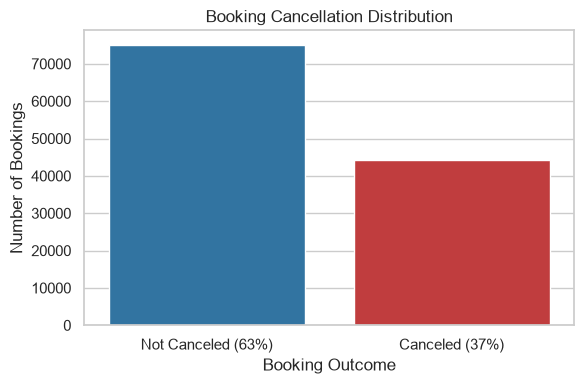

In [2]:
cancel_counts = df['is_canceled'].value_counts()
cancel_rate = df['is_canceled'].mean() * 100

print(f"Completed Stays (0): {cancel_counts[0]:,} ({100 - cancel_rate:.1f}%)")
print(f"Canceled Bookings (1): {cancel_counts[1]:,} ({cancel_rate:.1f}%)")

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='is_canceled', palette=['#1f77b4', '#d62728'])
plt.title('Booking Cancellation Distribution')
plt.xlabel('Booking Outcome')
plt.ylabel('Number of Bookings')
plt.xticks([0, 1], ['Not Canceled (63%)', 'Canceled (37%)'])
plt.tight_layout()
plt.savefig(f'{output_dir}/target_distribution.png', dpi=300)
plt.show()

## 2. Missing Values Analysis
We identify which columns have missing values and calculate their percentages.

In [3]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing_df = pd.DataFrame({
    'Missing_Rows': missing,
    'Percentage': (missing / len(df) * 100).round(2)
})

missing_df.to_csv(f'{output_dir}/missing_values_summary.csv')
print("Missing Values:")
missing_df

Missing Values:


,Missing_Rows,Percentage
company,112593,94.31
agent,16340,13.69
country,488,0.41
children,4,0.00


## 3. Key Categorical Factors
We examine cancellation rates across hotel types, deposit policies, and market segments.

C:\Users\abdel\AppData\Local\Temp\ipykernel_24712\3499174304.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='hotel', y='is_canceled', ax=axes[0], palette='Blues_d')


C:\Users\abdel\AppData\Local\Temp\ipykernel_24712\3499174304.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='deposit_type', y='is_canceled', ax=axes[1], palette='Reds_d')


C:\Users\abdel\AppData\Local\Temp\ipykernel_24712\3499174304.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='market_segment', y='is_canceled', ax=axes[2], palette='Greens_d')


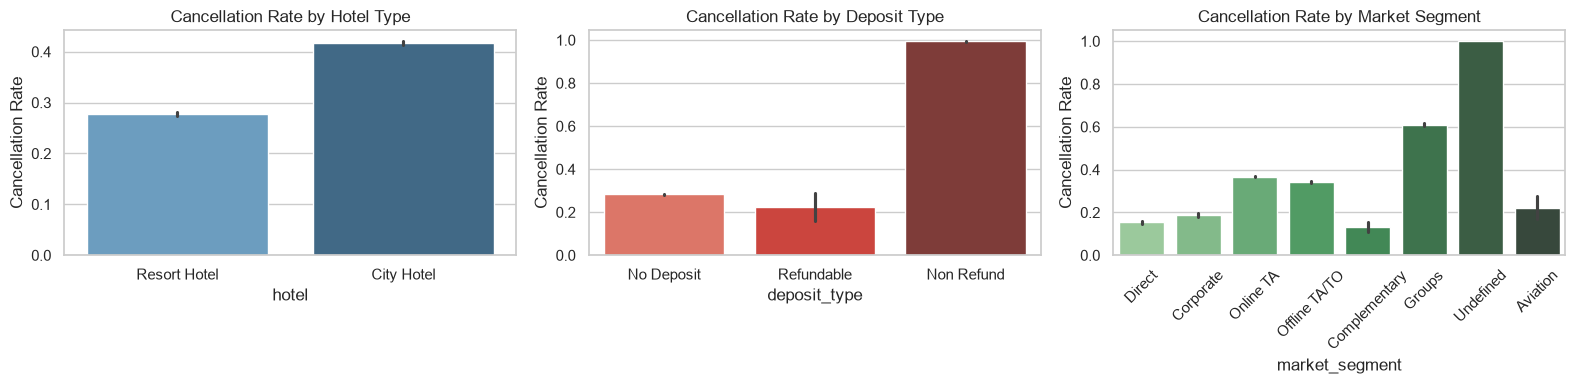

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Hotel type
sns.barplot(data=df, x='hotel', y='is_canceled', ax=axes[0], palette='Blues_d')
axes[0].set_title('Cancellation Rate by Hotel Type')
axes[0].set_ylabel('Cancellation Rate')

# Deposit type
sns.barplot(data=df, x='deposit_type', y='is_canceled', ax=axes[1], palette='Reds_d')
axes[1].set_title('Cancellation Rate by Deposit Type')
axes[1].set_ylabel('Cancellation Rate')

# Market segment
sns.barplot(data=df, x='market_segment', y='is_canceled', ax=axes[2], palette='Greens_d')
axes[2].set_title('Cancellation Rate by Market Segment')
axes[2].set_ylabel('Cancellation Rate')
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig(f'{output_dir}/cancellation_by_categories.png', dpi=300)
plt.show()

## 4. Key Numeric Factors: Lead Time & Room Price (ADR)
We compare lead time (days between booking and arrival) and Average Daily Rate (ADR) between canceled and completed bookings.

C:\Users\abdel\AppData\Local\Temp\ipykernel_24712\2879710561.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='is_canceled', y='lead_time', ax=axes[0], palette=['#1f77b4', '#d62728'])
C:\Users\abdel\AppData\Local\Temp\ipykernel_24712\2879710561.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(['Not Canceled', 'Canceled'])


C:\Users\abdel\AppData\Local\Temp\ipykernel_24712\2879710561.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df[df['adr'] < 500], x='is_canceled', y='adr', ax=axes[1], palette=['#1f77b4', '#d62728'])
C:\Users\abdel\AppData\Local\Temp\ipykernel_24712\2879710561.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1].set_xticklabels(['Not Canceled', 'Canceled'])


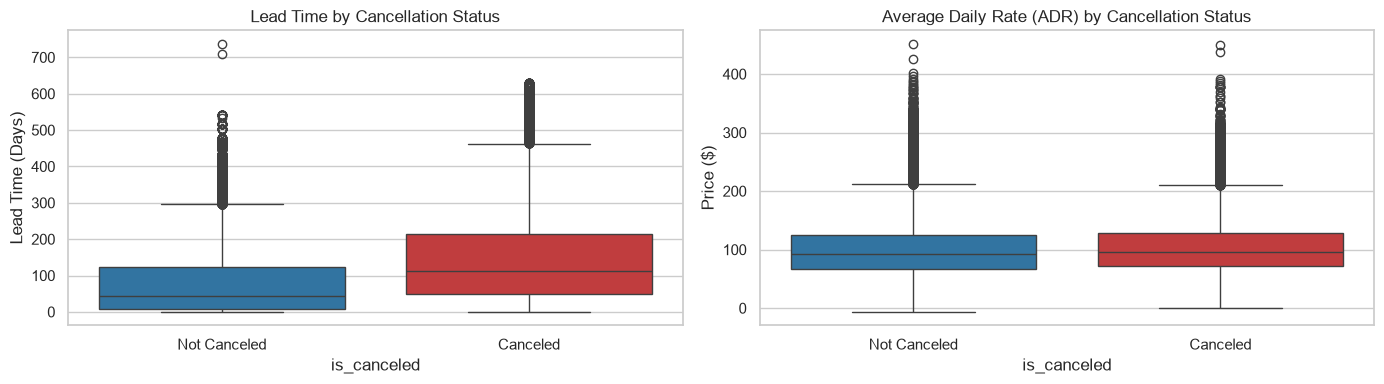

Median Values by Booking Status:
             lead_time   adr
is_canceled                 
0                 45.0  92.5
1                113.0  96.2


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Lead time
sns.boxplot(data=df, x='is_canceled', y='lead_time', ax=axes[0], palette=['#1f77b4', '#d62728'])
axes[0].set_title('Lead Time by Cancellation Status')
axes[0].set_xticklabels(['Not Canceled', 'Canceled'])
axes[0].set_ylabel('Lead Time (Days)')

# ADR (excluding extreme outlier for clear visualization)
sns.boxplot(data=df[df['adr'] < 500], x='is_canceled', y='adr', ax=axes[1], palette=['#1f77b4', '#d62728'])
axes[1].set_title('Average Daily Rate (ADR) by Cancellation Status')
axes[1].set_xticklabels(['Not Canceled', 'Canceled'])
axes[1].set_ylabel('Price ($)')

plt.tight_layout()
plt.savefig(f'{output_dir}/lead_time_and_adr_boxplots.png', dpi=300)
plt.show()

# Print summary comparison
summary_stats = df.groupby('is_canceled')[['lead_time', 'adr']].median()
summary_stats.to_csv(f'{output_dir}/lead_time_adr_medians.csv')
print("Median Values by Booking Status:")
print(summary_stats)

## Summary of Exploration Findings:
1. **Target Ratio:** 37.0% of bookings are canceled and 63.0% are completed.
2. **Deposit Paradox:** Bookings with 'Non Refund' deposits have a 99% cancellation rate, primarily from wholesale group bookings made far in advance.
3. **Lead Time:** Canceled bookings have much higher lead times (median 113 days vs. 45 days).
4. **Missing Values:** Found in `company` (94%), `agent` (14%), `country` (<1%), and `children` (4 rows).